In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility and display settings
RANDOM_STATE = 42

sns.set_theme(style="whitegrid", context="notebook")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# Locate the project root
cwd = Path.cwd()

if (cwd / "data" / "raw" / "ai4i2020.csv").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw" / "ai4i2020.csv").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find data/raw/ai4i2020.csv. "
        "Place the dataset in the agreed project structure."
    )

# Define input and output paths
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

PLOTS_DIR = PROJECT_ROOT / "artifacts" / "plots"
REPORTS_DIR = PROJECT_ROOT / "artifacts" / "reports"

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")
print(f"Plots directory: {PLOTS_DIR}")
print(f"Reports directory: {REPORTS_DIR}")


Project root: d:\robotic-predictive-maintenance
Dataset path: d:\robotic-predictive-maintenance\data\raw\ai4i2020.csv
Plots directory: d:\robotic-predictive-maintenance\artifacts\plots
Reports directory: d:\robotic-predictive-maintenance\artifacts\reports


In [2]:
# Load the original dataset without modifying it
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")


Dataset loaded successfully.
Number of rows    : 10,000
Number of columns : 14


In [3]:
print("First 5 observations:")
display(df.head())

print("\nLast 5 observations:")
display(df.tail())


First 5 observations:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,2,L47181,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,3,L47182,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,4,L47183,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,5,L47184,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0



Last 5 observations:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.800,308.400,1604,29.500,14,0,0,0,0,0,0
9996,9997,H39410,H,298.900,308.400,1632,31.800,17,0,0,0,0,0,0
9997,9998,M24857,M,299.000,308.600,1645,33.400,22,0,0,0,0,0,0
9998,9999,H39412,H,299.000,308.700,1408,48.500,25,0,0,0,0,0,0
9999,10000,M24859,M,299.000,308.700,1500,40.200,30,0,0,0,0,0,0


In [4]:
display(df.sample(n=min(5, len(df)), random_state=RANDOM_STATE))


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
6252,6253,L53432,L,300.800,310.300,1538,36.100,198,0,0,0,0,0,0
4684,4685,M19544,M,303.600,311.800,1421,44.800,101,1,0,0,0,0,0
1731,1732,M16591,M,298.300,307.900,1485,42.000,117,0,0,0,0,0,0
4742,4743,L51922,L,303.300,311.300,1592,33.700,14,0,0,0,0,0,0
4521,4522,L51701,L,302.400,310.400,1865,23.900,129,0,0,0,0,0,0


In [5]:
print("Column names:")
for column in df.columns:
    print(f"- {column}")

print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())

Column names:
- UDI
- Product ID
- Type
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]
- Machine failure
- TWF
- HDF
- PWF
- OSF
- RNF

Data types:


,data_type
UDI,int64
Product ID,str
Type,str
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [6]:
print("Dataset information:")
df.info()

print("\nNumerical feature summary:")
display(df.describe().T)

print("\nSummary of all columns, including categorical columns:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3)

,count,mean,std,min,25%,50%,75%,max
UDI,10000.000,5000.500,2886.896,1.000,2500.750,5000.500,7500.250,10000.000
Air temperature [K],10000.000,300.005,2.000,295.300,298.300,300.100,301.500,304.500
Process temperature [K],10000.000,310.006,1.484,305.700,308.800,310.100,311.100,313.800
Rotational speed [rpm],10000.000,1538.776,179.284,1168.000,1423.000,1503.000,1612.000,2886.000
Torque [Nm],10000.000,39.987,9.969,3.800,33.200,40.100,46.800,76.600
Tool wear [min],10000.000,107.951,63.654,0.000,53.000,108.000,162.000,253.000
Machine failure,10000.000,0.034,0.181,0.000,0.000,0.000,0.000,1.000
TWF,10000.000,0.005,0.068,0.000,0.000,0.000,0.000,1.000
HDF,10000.000,0.011,0.107,0.000,0.000,0.000,0.000,1.000
PWF,10000.000,0.009,0.097,0.000,0.000,0.000,0.000,1.000



Summary of all columns, including categorical columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.000,NaN,NaN,NaN,5000.500,2886.896,1.000,2500.750,5000.500,7500.250,10000.000
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.000,NaN,NaN,NaN,300.005,2.000,295.300,298.300,300.100,301.500,304.500
Process temperature [K],10000.000,NaN,NaN,NaN,310.006,1.484,305.700,308.800,310.100,311.100,313.800
Rotational speed [rpm],10000.000,NaN,NaN,NaN,1538.776,179.284,1168.000,1423.000,1503.000,1612.000,2886.000
Torque [Nm],10000.000,NaN,NaN,NaN,39.987,9.969,3.800,33.200,40.100,46.800,76.600
Tool wear [min],10000.000,NaN,NaN,NaN,107.951,63.654,0.000,53.000,108.000,162.000,253.000
Machine failure,10000.000,NaN,NaN,NaN,0.034,0.181,0.000,0.000,0.000,0.000,1.000
TWF,10000.000,NaN,NaN,NaN,0.005,0.068,0.000,0.000,0.000,0.000,1.000


In [7]:
# Count missing values in each column
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100,
})

missing_summary = missing_summary.sort_values(
    by="missing_count",
    ascending=False
)

display(missing_summary)

total_missing = int(df.isnull().sum().sum())

print(f"Total missing values: {total_missing}")

if total_missing == 0:
    print("No missing values detected.")
else:
    print("Missing values detected. Investigate before preprocessing.")


,missing_count,missing_percentage
UDI,0,0.000
Product ID,0,0.000
Type,0,0.000
Air temperature [K],0,0.000
Process temperature [K],0,0.000
Rotational speed [rpm],0,0.000
Torque [Nm],0,0.000
Tool wear [min],0,0.000
Machine failure,0,0.000
TWF,0,0.000


Total missing values: 0
No missing values detected.


In [8]:
# Check exact duplicate rows
duplicate_rows = df.duplicated().sum()

# Check repeated UDI identifiers
duplicate_udi = df["UDI"].duplicated().sum()

# Check repeated Product IDs
duplicate_product_ids = df["Product ID"].duplicated().sum()

print(f"Exact duplicate rows       : {duplicate_rows}")
print(f"Duplicate UDI identifiers  : {duplicate_udi}")
print(f"Duplicate Product IDs      : {duplicate_product_ids}")

Exact duplicate rows       : 0
Duplicate UDI identifiers  : 0
Duplicate Product IDs      : 0


In [9]:
# Inspect the values and counts of categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

for column in categorical_columns:
    print(f"\nColumn: {column}")
    print(f"Unique values: {df[column].nunique(dropna=False)}")
    display(df[column].value_counts(dropna=False))


Column: Product ID
Unique values: 10000


Product ID
M14860    1
L47181    1
L47182    1
L47183    1
L47184    1
         ..
M24855    1
H39410    1
M24857    1
H39412    1
M24859    1
Name: count, Length: 10000, dtype: int64


Column: Type
Unique values: 3


Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [10]:
# Define the target and individual failure-mode columns
TARGET_COLUMN = "Machine failure"

FAILURE_MODE_COLUMNS = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF",
]

BINARY_COLUMNS = [TARGET_COLUMN] + FAILURE_MODE_COLUMNS

# Check that binary columns contain only 0 and 1
for column in BINARY_COLUMNS:
    observed_values = set(df[column].dropna().unique())
    invalid_values = observed_values - {0, 1}

    print(
        f"{column}: "
        f"unique values={sorted(observed_values)}, "
        f"invalid values={invalid_values}"
    )


Machine failure: unique values=[np.int64(0), np.int64(1)], invalid values=set()
TWF: unique values=[np.int64(0), np.int64(1)], invalid values=set()
HDF: unique values=[np.int64(0), np.int64(1)], invalid values=set()
PWF: unique values=[np.int64(0), np.int64(1)], invalid values=set()
OSF: unique values=[np.int64(0), np.int64(1)], invalid values=set()
RNF: unique values=[np.int64(0), np.int64(1)], invalid values=set()


In [11]:
target_counts = df[TARGET_COLUMN].value_counts().reindex(
    [0, 1],
    fill_value=0
)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_counts / len(df) * 100,
})

target_summary.index.name = TARGET_COLUMN

display(target_summary)

failure_count = int((df[TARGET_COLUMN] == 1).sum())
non_failure_count = int((df[TARGET_COLUMN] == 0).sum())

print(f"Non-failure observations: {non_failure_count:,}")
print(f"Failure observations    : {failure_count:,}")
print(f"Failure rate             : {failure_count / len(df) * 100:.3f}%")
print(f"Non-failure rate         : {non_failure_count / len(df) * 100:.3f}%")


,count,percentage
Machine failure,,
0,9661,96.610
1,339,3.390


Non-failure observations: 9,661
Failure observations    : 339
Failure rate             : 3.390%
Non-failure rate         : 96.610%


In [12]:
# Check whether at least one failure-mode label is active
df_eda_check = df.copy()

df_eda_check["any_failure_mode"] = (
    df_eda_check[FAILURE_MODE_COLUMNS].eq(1).any(axis=1).astype(int)
)

# Compare the overall target with the failure-mode labels
df_eda_check["label_mismatch"] = (
    df_eda_check[TARGET_COLUMN] != df_eda_check["any_failure_mode"]
)

print("Overall target vs. individual failure modes")
print(
    "Rows with at least one failure mode:",
    int(df_eda_check["any_failure_mode"].sum())
)
print(
    "Rows labelled as machine failures:",
    int(df_eda_check[TARGET_COLUMN].sum())
)
print(
    "Rows where the labels disagree:",
    int(df_eda_check["label_mismatch"].sum())
)

display(
    pd.crosstab(
        df_eda_check[TARGET_COLUMN],
        df_eda_check["any_failure_mode"],
        rownames=["Machine failure"],
        colnames=["Any failure mode"]
    )
)

if df_eda_check["label_mismatch"].any():
    print("\nExample rows with label disagreements:")
    display(
        df_eda_check.loc[
            df_eda_check["label_mismatch"],
            ["UDI", TARGET_COLUMN] + FAILURE_MODE_COLUMNS
        ].head(10)
    )
else:
    print("\nThe overall target agrees with the combined failure-mode labels.")


Overall target vs. individual failure modes
Rows with at least one failure mode: 348
Rows labelled as machine failures: 339
Rows where the labels disagree: 27


Any failure mode,0,1
Machine failure,,
0,9643,18
1,9,330



Example rows with label disagreements:


,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


In [13]:
# Extract all rows where the overall label and failure-mode labels disagree
label_mismatches = df_eda_check.loc[
    df_eda_check["label_mismatch"],
    ["UDI", TARGET_COLUMN] + FAILURE_MODE_COLUMNS
].copy()

mismatch_report_path = REPORTS_DIR / "label_disagreements.csv"
label_mismatches.to_csv(mismatch_report_path, index=False)

print(f"Total disagreements: {len(label_mismatches)}")
print(f"Report saved to: {mismatch_report_path}")

display(label_mismatches)

Total disagreements: 27
Report saved to: d:\robotic-predictive-maintenance\artifacts\reports\label_disagreements.csv


,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


In [14]:
target_counts = df[TARGET_COLUMN].value_counts().reindex(
    [0, 1],
    fill_value=0
)

target_percentages = (
    df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .reindex([0, 1], fill_value=0)
    .mul(100)
)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages,
})

target_summary.index = ["No Failure (0)", "Failure (1)"]
target_summary.index.name = "Class"

display(target_summary)

majority_class_percentage = target_percentages.max()
minority_class_percentage = target_percentages.min()

print(f"Majority class percentage: {majority_class_percentage:.2f}%")
print(f"Minority class percentage: {minority_class_percentage:.2f}%")
print(
    "Majority-to-minority ratio:",
    f"{target_counts.max() / target_counts.min():.2f}:1"
)


,count,percentage
Class,,
No Failure (0),9661,96.610
Failure (1),339,3.390


Majority class percentage: 96.61%
Minority class percentage: 3.39%
Majority-to-minority ratio: 28.50:1


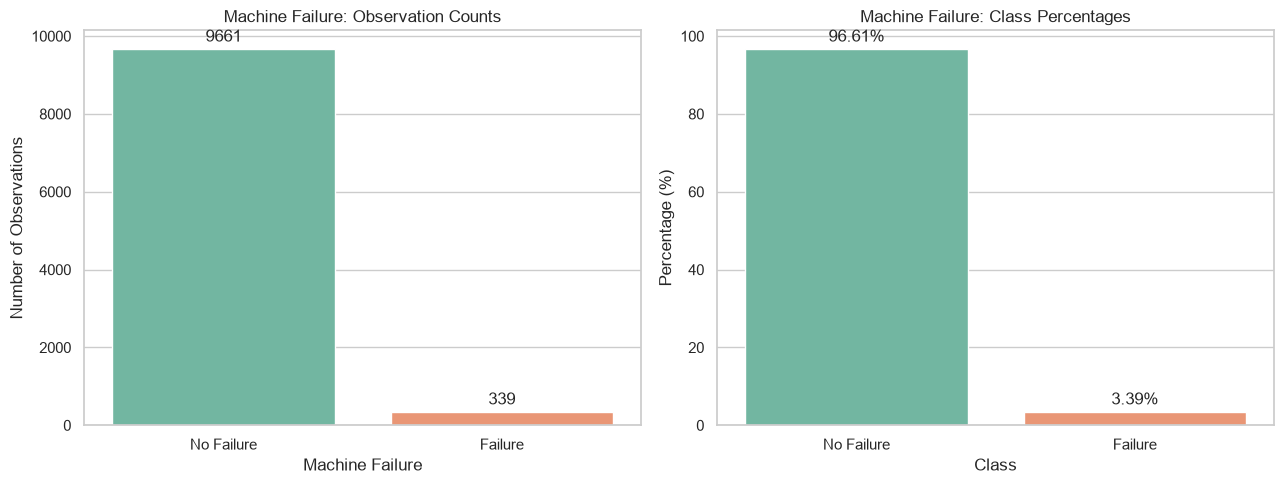

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\target_class_distribution.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

class_labels = ["No Failure", "Failure"]
colors = sns.color_palette("Set2", n_colors=2)

# Count plot
sns.countplot(
    data=df,
    x=TARGET_COLUMN,
    hue=TARGET_COLUMN,
    order=[0, 1],
    hue_order=[0, 1],
    palette=colors,
    legend=False,
    ax=axes[0],
)

axes[0].set_title("Machine Failure: Observation Counts")
axes[0].set_xlabel("Machine Failure")
axes[0].set_ylabel("Number of Observations")
axes[0].set_xticks([0, 1], class_labels)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

# Percentage plot
sns.barplot(
    x=class_labels,
    y=[
        target_percentages.loc[0],
        target_percentages.loc[1],
    ],
    hue=class_labels,
    palette=colors,
    legend=False,
    ax=axes[1],
)

axes[1].set_title("Machine Failure: Class Percentages")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Percentage (%)")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()

plot_path = PLOTS_DIR / "target_class_distribution.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")

In [16]:
majority_class = int(df[TARGET_COLUMN].value_counts().idxmax())

majority_baseline_accuracy = (
    df[TARGET_COLUMN].eq(majority_class).mean() * 100
)

print(f"Majority class prediction: {majority_class}")
print(
    "Accuracy from always predicting the majority class: "
    f"{majority_baseline_accuracy:.2f}%"
)

print(
    "\nInterpretation: this classifier never detects a machine failure, "
    "even though it may achieve high accuracy."
)

Majority class prediction: 0
Accuracy from always predicting the majority class: 96.61%

Interpretation: this classifier never detects a machine failure, even though it may achieve high accuracy.


In [17]:
NUMERICAL_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

print("Numerical operating features:")
for feature in NUMERICAL_FEATURES:
    print(f"- {feature}")

print(f"\nTotal numerical operating features: {len(NUMERICAL_FEATURES)}")

Numerical operating features:
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]

Total numerical operating features: 5


In [18]:
numerical_summary = df[NUMERICAL_FEATURES].describe().T

numerical_summary["median"] = df[NUMERICAL_FEATURES].median()
numerical_summary["skewness"] = df[NUMERICAL_FEATURES].skew()
numerical_summary["variance"] = df[NUMERICAL_FEATURES].var()

display(numerical_summary.round(3))

summary_path = REPORTS_DIR / "numerical_feature_summary.csv"
numerical_summary.to_csv(summary_path)

print(f"Summary saved to: {summary_path}")

,count,mean,std,min,25%,50%,75%,max,median,skewness,variance
Air temperature [K],10000.000,300.005,2.000,295.300,298.300,300.100,301.500,304.500,300.100,0.114,4.001
Process temperature [K],10000.000,310.006,1.484,305.700,308.800,310.100,311.100,313.800,310.100,0.015,2.201
Rotational speed [rpm],10000.000,1538.776,179.284,1168.000,1423.000,1503.000,1612.000,2886.000,1503.000,1.993,32142.787
Torque [Nm],10000.000,39.987,9.969,3.800,33.200,40.100,46.800,76.600,40.100,-0.010,99.380
Tool wear [min],10000.000,107.951,63.654,0.000,53.000,108.000,162.000,253.000,108.000,0.027,4051.850


Summary saved to: d:\robotic-predictive-maintenance\artifacts\reports\numerical_feature_summary.csv


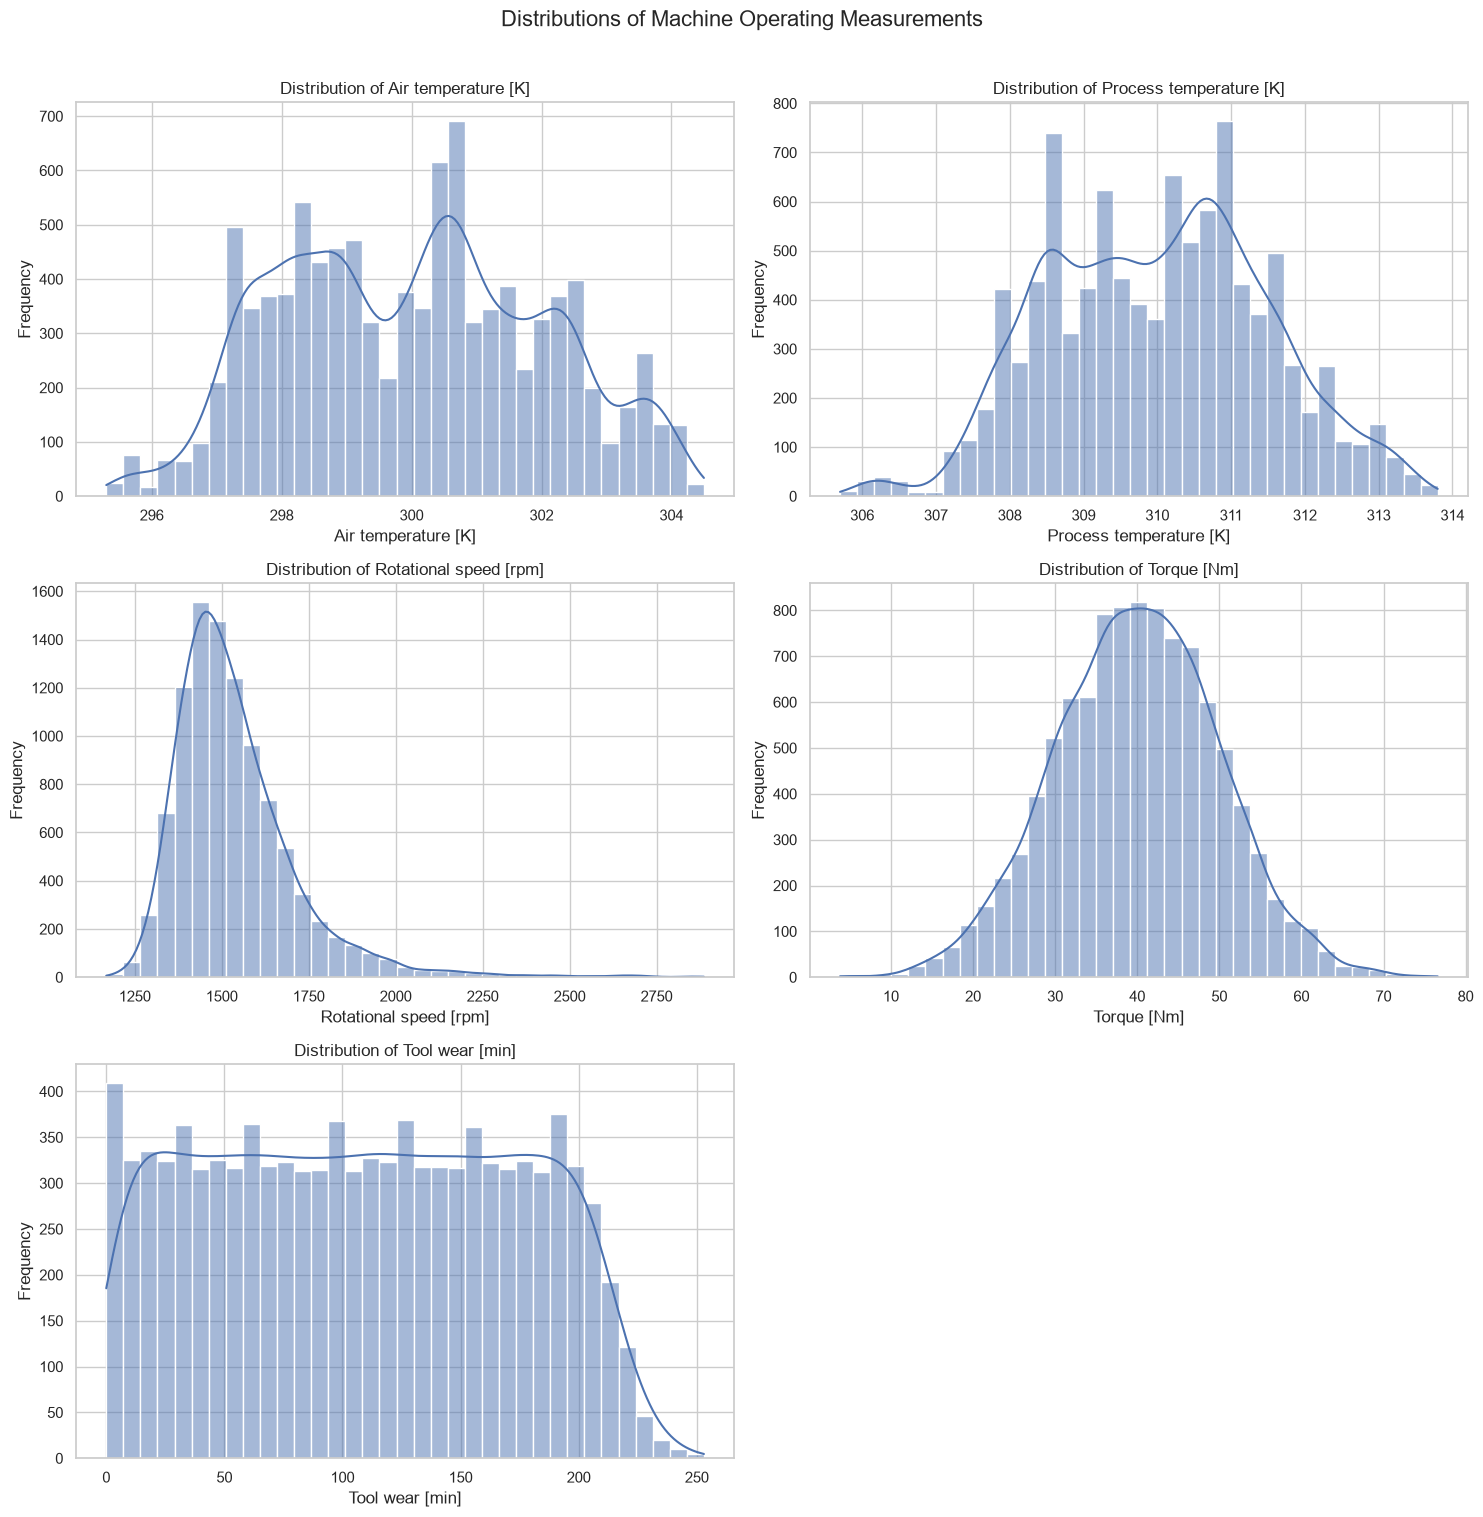

Distribution plots saved to: d:\robotic-predictive-maintenance\artifacts\plots\numerical_feature_distributions.png


In [19]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, feature in enumerate(NUMERICAL_FEATURES):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=35,
        ax=axes[i],
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

# Remove the unused sixth subplot
fig.delaxes(axes[-1])

fig.suptitle(
    "Distributions of Machine Operating Measurements",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()

plot_path = PLOTS_DIR / "numerical_feature_distributions.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Distribution plots saved to: {plot_path}")

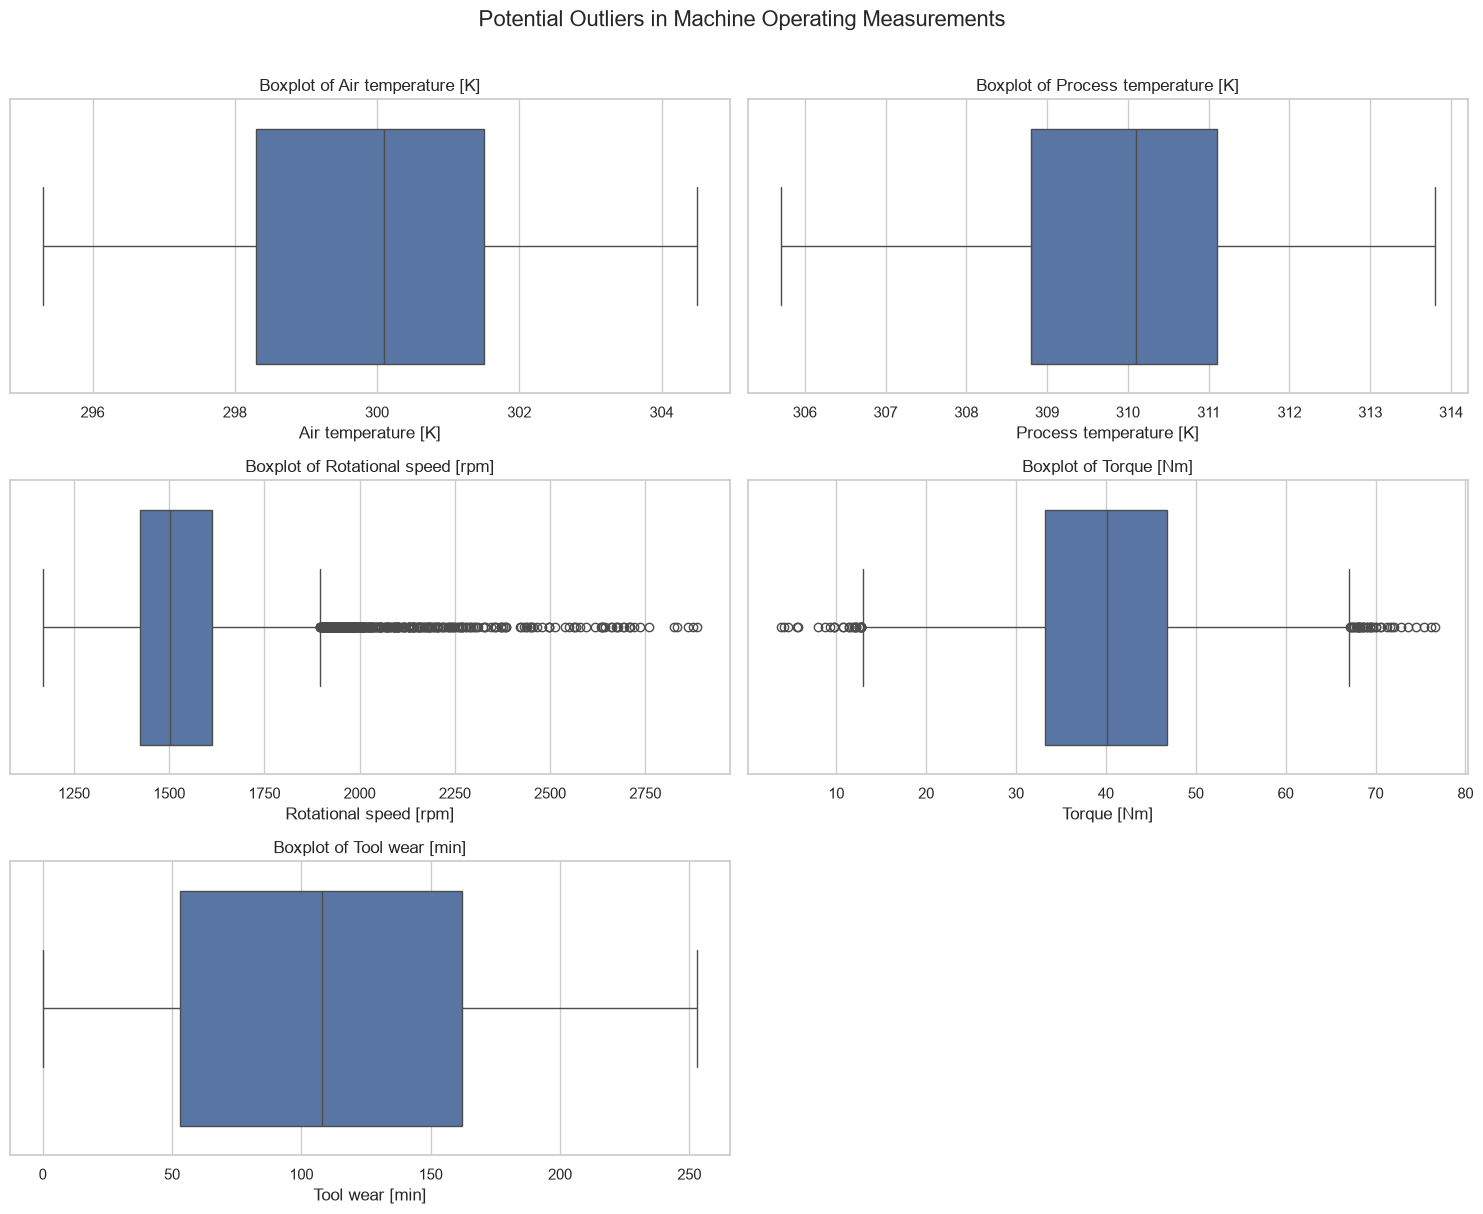

Boxplots saved to: d:\robotic-predictive-maintenance\artifacts\plots\numerical_feature_boxplots.png


In [20]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, feature in enumerate(NUMERICAL_FEATURES):
    sns.boxplot(
        data=df,
        x=feature,
        ax=axes[i],
    )

    axes[i].set_title(f"Boxplot of {feature}")
    axes[i].set_xlabel(feature)

fig.delaxes(axes[-1])

fig.suptitle(
    "Potential Outliers in Machine Operating Measurements",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()

plot_path = PLOTS_DIR / "numerical_feature_boxplots.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Boxplots saved to: {plot_path}")


In [21]:
outlier_results = []

for feature in NUMERICAL_FEATURES:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)

    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df[feature] < lower_bound)
        | (df[feature] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_results.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": outlier_count / len(df) * 100,
    })

outlier_summary = pd.DataFrame(outlier_results).set_index("feature")

display(outlier_summary.round(3))

outlier_path = REPORTS_DIR / "iqr_outlier_summary.csv"
outlier_summary.to_csv(outlier_path)

print(f"Outlier summary saved to: {outlier_path}")


,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
feature,,,,,,,
Air temperature [K],298.300,301.500,3.200,293.500,306.300,0,0.000
Process temperature [K],308.800,311.100,2.300,305.350,314.550,0,0.000
Rotational speed [rpm],1423.000,1612.000,189.000,1139.500,1895.500,418,4.180
Torque [Nm],33.200,46.800,13.600,12.800,67.200,69,0.690
Tool wear [min],53.000,162.000,109.000,-110.500,325.500,0,0.000


Outlier summary saved to: d:\robotic-predictive-maintenance\artifacts\reports\iqr_outlier_summary.csv


In [22]:
extreme_records = []

for feature in NUMERICAL_FEATURES:
    min_index = df[feature].idxmin()
    max_index = df[feature].idxmax()

    extreme_records.append({
        "feature": feature,
        "minimum_value": df.loc[min_index, feature],
        "minimum_UDI": df.loc[min_index, "UDI"],
        "minimum_failure_label": df.loc[min_index, TARGET_COLUMN],
        "maximum_value": df.loc[max_index, feature],
        "maximum_UDI": df.loc[max_index, "UDI"],
        "maximum_failure_label": df.loc[max_index, TARGET_COLUMN],
    })

extreme_summary = pd.DataFrame(extreme_records).set_index("feature")

display(extreme_summary)


,minimum_value,minimum_UDI,minimum_failure_label,maximum_value,maximum_UDI,maximum_failure_label
feature,,,,,,
Air temperature [K],295.300,917,0,304.500,5146,0
Process temperature [K],305.700,918,0,313.800,5115,0
Rotational speed [rpm],1168.000,995,0,2886.000,1785,1
Torque [Nm],3.800,1785,1,76.600,7764,1
Tool wear [min],0.000,1,0,253.000,5402,1


In [23]:
TYPE_COLUMN = "Type"

type_counts = df[TYPE_COLUMN].value_counts().reindex(
    ["L", "M", "H"],
    fill_value=0,
)

type_summary = pd.DataFrame({
    "count": type_counts,
    "percentage": type_counts / len(df) * 100,
})

type_summary.index.name = "Product Type"

display(type_summary)

print("Unique product types:", df[TYPE_COLUMN].nunique())
print("Observed categories:", sorted(df[TYPE_COLUMN].dropna().unique()))


,count,percentage
Product Type,,
L,6000,60.000
M,2997,29.970
H,1003,10.030


Unique product types: 3
Observed categories: ['H', 'L', 'M']


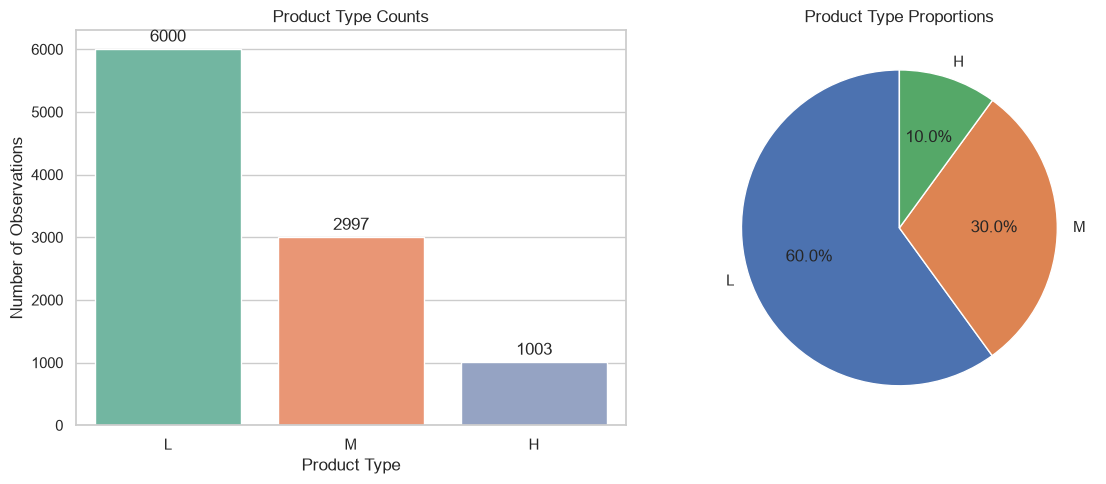

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\product_type_distribution.png


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

type_plot_data = type_summary.reset_index()

sns.barplot(
    data=type_plot_data,
    x="Product Type",
    y="count",
    hue="Product Type",
    order=["L", "M", "H"],
    palette="Set2",
    legend=False,
    ax=axes[0],
)

axes[0].set_title("Product Type Counts")
axes[0].set_xlabel("Product Type")
axes[0].set_ylabel("Number of Observations")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

axes[1].pie(
    type_summary["count"],
    labels=type_summary.index,
    autopct="%1.1f%%",
    startangle=90,
)

axes[1].set_title("Product Type Proportions")

plt.tight_layout()

plot_path = PLOTS_DIR / "product_type_distribution.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [25]:
type_failure_summary = (
    df.groupby(TYPE_COLUMN, observed=False)[TARGET_COLUMN]
    .agg(
        total_observations="size",
        failure_count="sum",
        failure_rate="mean",
    )
)

type_failure_summary["non_failure_count"] = (
    type_failure_summary["total_observations"]
    - type_failure_summary["failure_count"]
)

type_failure_summary["failure_rate_pct"] = (
    type_failure_summary["failure_rate"] * 100
)

type_failure_summary = type_failure_summary[
    [
        "total_observations",
        "non_failure_count",
        "failure_count",
        "failure_rate_pct",
    ]
].reindex(["L", "M", "H"])

display(type_failure_summary.round(3))

type_failure_path = REPORTS_DIR / "failure_rate_by_product_type.csv"
type_failure_summary.to_csv(type_failure_path)

print(f"Summary saved to: {type_failure_path}")

,total_observations,non_failure_count,failure_count,failure_rate_pct
Type,,,,
L,6000,5765,235,3.917
M,2997,2914,83,2.769
H,1003,982,21,2.094


Summary saved to: d:\robotic-predictive-maintenance\artifacts\reports\failure_rate_by_product_type.csv


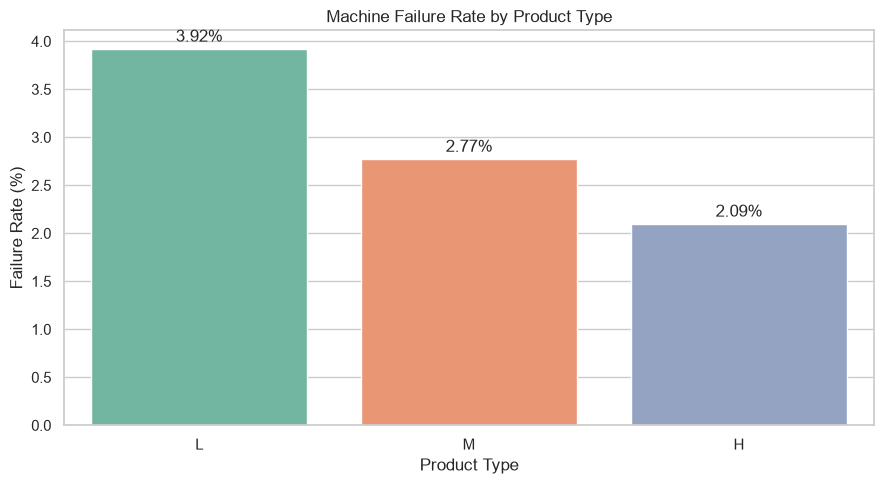

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\failure_rate_by_product_type.png


In [26]:
plot_data = type_failure_summary.reset_index()

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x=TYPE_COLUMN,
    y="failure_rate_pct",
    hue=TYPE_COLUMN,
    order=["L", "M", "H"],
    palette="Set2",
    legend=False,
    ax=ax,
)

ax.set_title("Machine Failure Rate by Product Type")
ax.set_xlabel("Product Type")
ax.set_ylabel("Failure Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()

plot_path = PLOTS_DIR / "failure_rate_by_product_type.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [27]:
failure_group_summary = (
    df.groupby(TARGET_COLUMN)[NUMERICAL_FEATURES]
    .agg(["mean", "median", "std"])
    .T
)

display(failure_group_summary.round(3))


Machine failure                       0        1
Air temperature [K]     mean    299.974  300.886
                        median  300.000  301.600
                        std       1.991    2.071
Process temperature [K] mean    309.996  310.290
                        median  310.000  310.400
                        std       1.487    1.364
Rotational speed [rpm]  mean   1540.260 1496.487
                        median 1507.000 1365.000
                        std     167.395  384.944
Torque [Nm]             mean     39.630   50.168
                        median   39.900   53.700
                        std       9.472   16.374
Tool wear [min]         mean    106.694  143.782
                        median  107.000  165.000
                        std      62.946   72.760

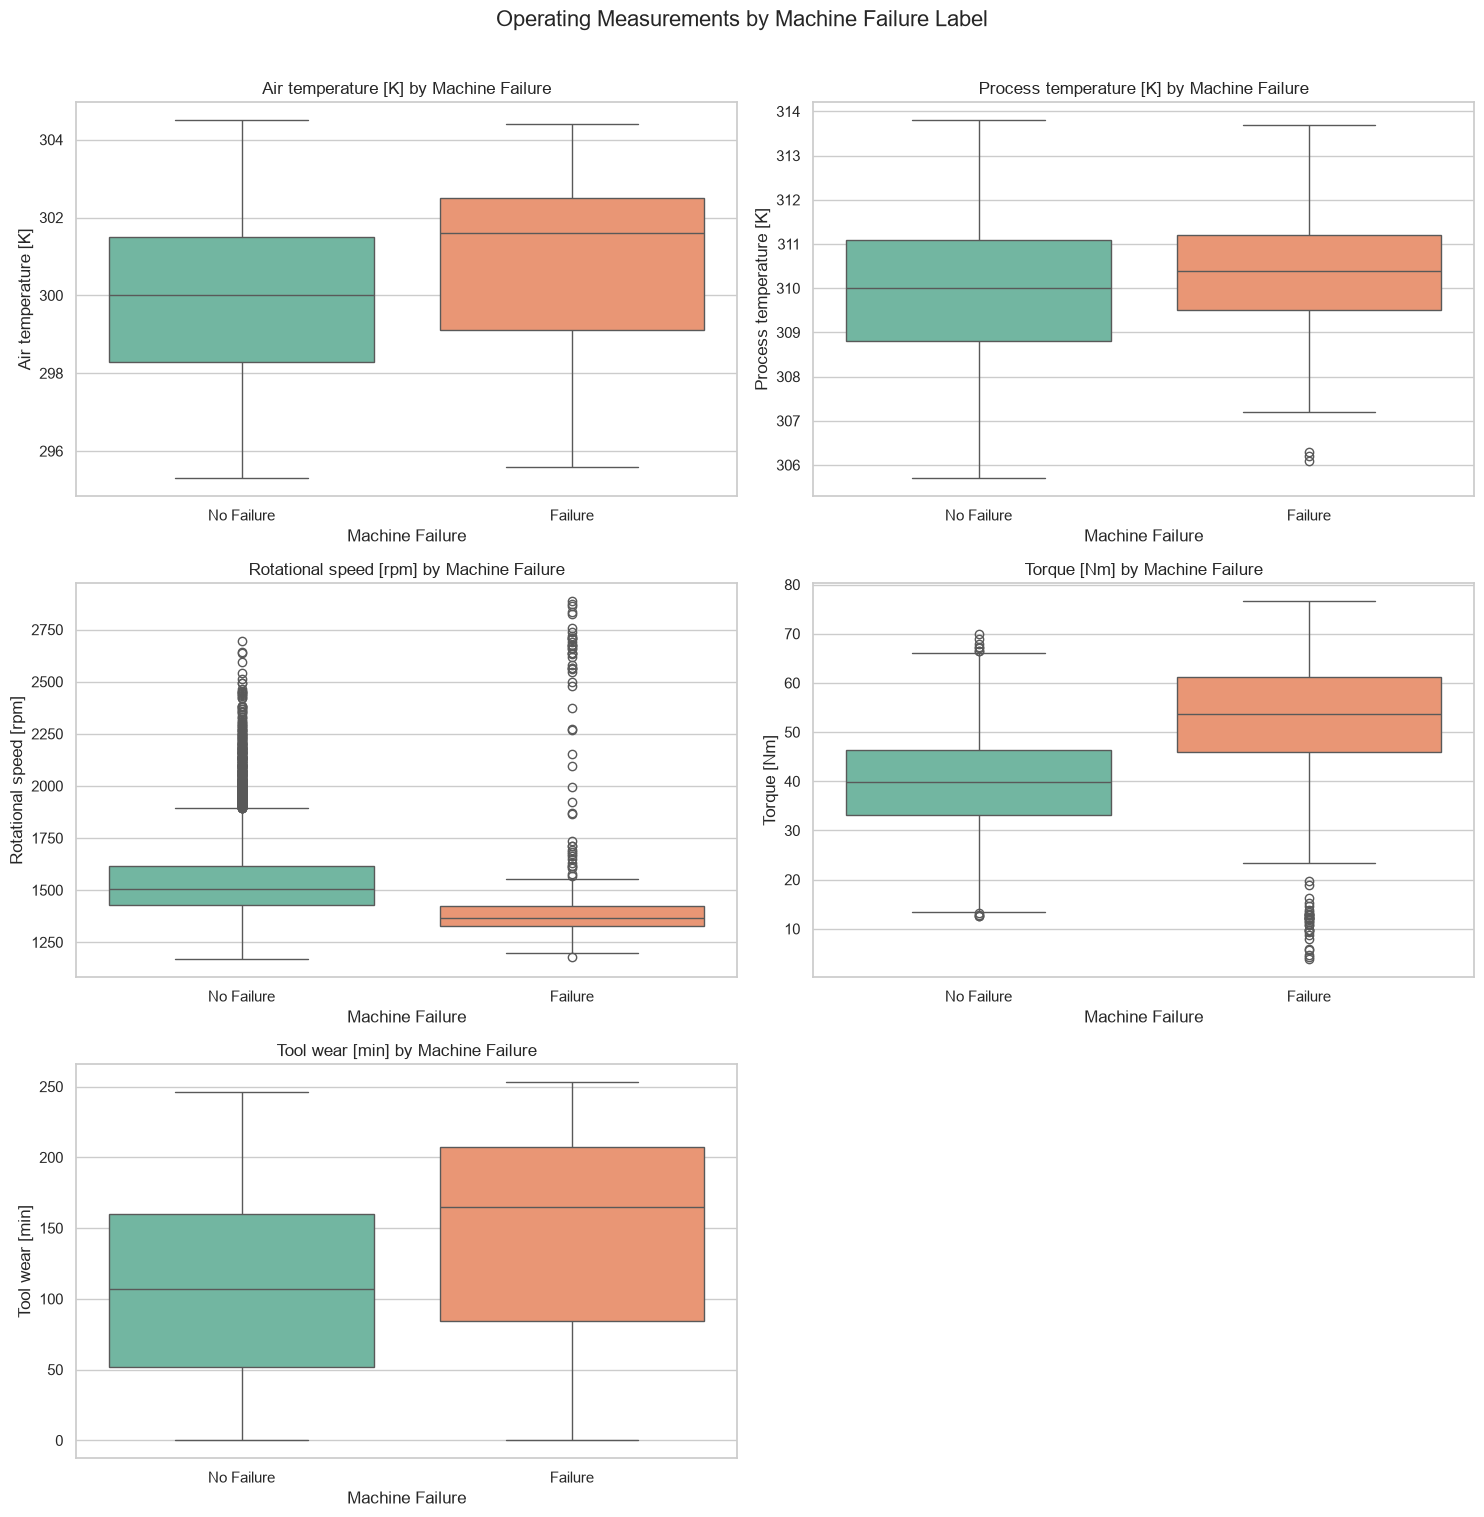

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\features_by_machine_failure_boxplots.png


In [28]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, feature in enumerate(NUMERICAL_FEATURES):
    sns.boxplot(
        data=df,
        x=TARGET_COLUMN,
        y=feature,
        hue=TARGET_COLUMN,
        order=[0, 1],
        palette="Set2",
        legend=False,
        ax=axes[i],
    )

    axes[i].set_title(f"{feature} by Machine Failure")
    axes[i].set_xlabel("Machine Failure")
    axes[i].set_ylabel(feature)
    axes[i].set_xticks([0, 1], ["No Failure", "Failure"])

fig.delaxes(axes[-1])

fig.suptitle(
    "Operating Measurements by Machine Failure Label",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()

plot_path = PLOTS_DIR / "features_by_machine_failure_boxplots.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


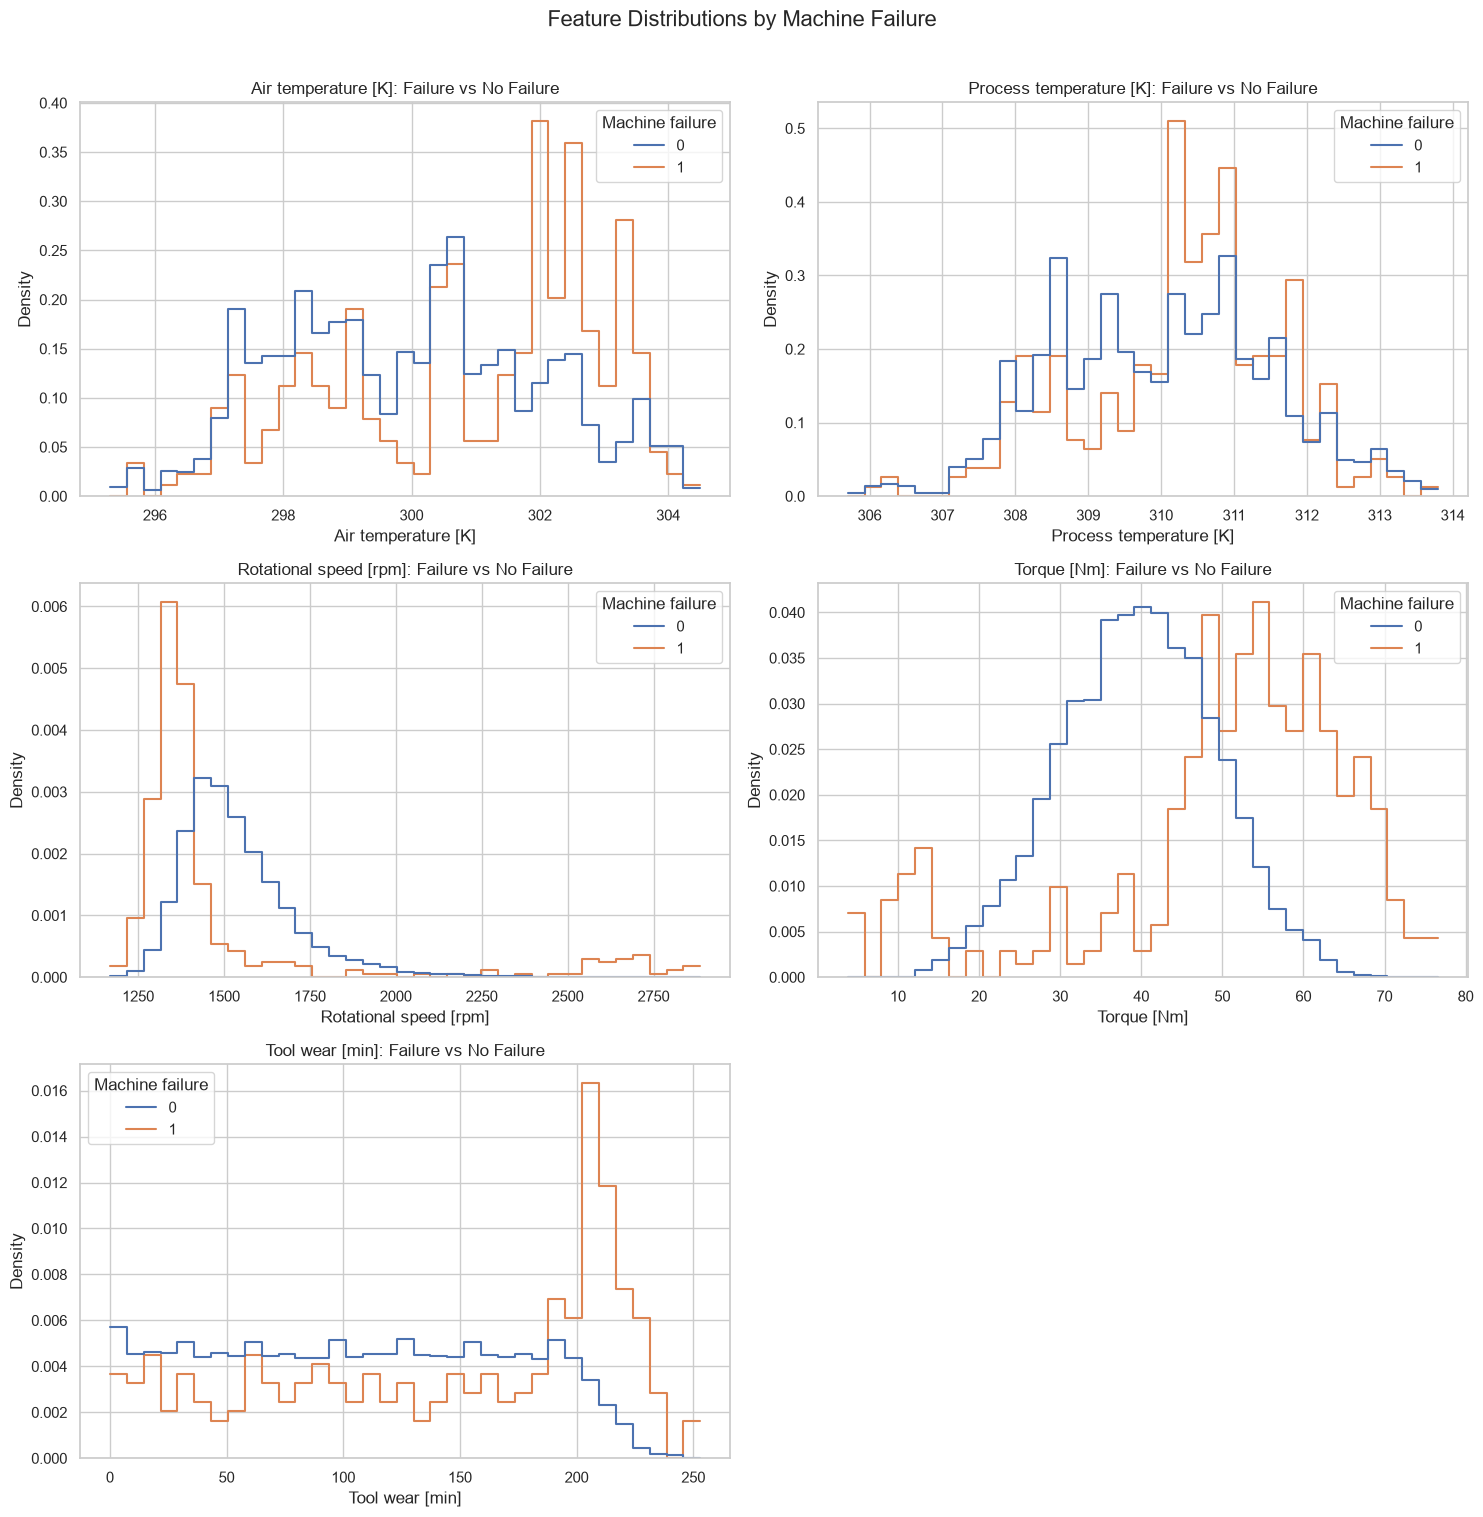

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\features_by_failure_distributions.png


In [29]:
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for i, feature in enumerate(NUMERICAL_FEATURES):
    sns.histplot(
        data=df,
        x=feature,
        hue=TARGET_COLUMN,
        hue_order=[0, 1],
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        bins=35,
        ax=axes[i],
    )

    axes[i].set_title(f"{feature}: Failure vs No Failure")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Density")

fig.delaxes(axes[-1])

fig.suptitle(
    "Feature Distributions by Machine Failure",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()

plot_path = PLOTS_DIR / "features_by_failure_distributions.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [30]:
failure_rate_by_bins = {}

for feature in NUMERICAL_FEATURES:
    temp = df[[feature, TARGET_COLUMN]].copy()

    temp["feature_bin"] = pd.qcut(
        temp[feature],
        q=10,
        duplicates="drop",
    )

    grouped = (
        temp.groupby("feature_bin", observed=True)[TARGET_COLUMN]
        .agg(
            observations="size",
            failures="sum",
            failure_rate="mean",
        )
        .reset_index()
    )

    grouped["failure_rate_pct"] = grouped["failure_rate"] * 100
    failure_rate_by_bins[feature] = grouped

    print(f"\nFailure rate by {feature}:")
    display(grouped.round(4))



Failure rate by Air temperature [K]:


,feature_bin,observations,failures,failure_rate,failure_rate_pct
0,"(295.29900000000004, 297.4]",1048,27,0.026,2.576
1,"(297.4, 298.1]",1087,19,0.018,1.748
2,"(298.1, 298.7]",974,23,0.024,2.361
3,"(298.7, 299.2]",930,25,0.027,2.688
4,"(299.2, 300.1]",1078,16,0.015,1.484
5,"(300.1, 300.6]",1013,25,0.025,2.468
6,"(300.6, 301.1]",906,24,0.026,2.649
7,"(301.1, 301.9]",971,36,0.037,3.708
8,"(301.9, 302.7]",1064,85,0.080,7.989
9,"(302.7, 304.5]",929,59,0.064,6.351



Failure rate by Process temperature [K]:


,feature_bin,observations,failures,failure_rate,failure_rate_pct
0,"(305.699, 308.1]",1064,28,0.026,2.632
1,"(308.1, 308.6]",1104,26,0.024,2.355
2,"(308.6, 309.1]",974,17,0.018,1.745
3,"(309.1, 309.6]",1069,18,0.017,1.684
4,"(309.6, 310.1]",1012,42,0.042,4.150
5,"(310.1, 310.5]",912,50,0.055,5.482
6,"(310.5, 310.9]",1101,53,0.048,4.814
7,"(310.9, 311.3]",843,30,0.036,3.559
8,"(311.3, 311.9]",969,47,0.049,4.850
9,"(311.9, 313.8]",952,28,0.029,2.941



Failure rate by Rotational speed [rpm]:


,feature_bin,observations,failures,failure_rate,failure_rate_pct
0,"(1167.999, 1364.0]",1016,168,0.165,16.535
1,"(1364.0, 1405.0]",991,76,0.077,7.669
2,"(1405.0, 1439.0]",1015,17,0.017,1.675
3,"(1439.0, 1470.0]",996,12,0.012,1.205
4,"(1470.0, 1503.0]",990,6,0.006,0.606
5,"(1503.0, 1541.0]",1009,6,0.006,0.595
6,"(1541.0, 1584.0]",986,5,0.005,0.507
7,"(1584.0, 1644.0]",1006,4,0.004,0.398
8,"(1644.0, 1746.0]",994,8,0.008,0.805
9,"(1746.0, 2886.0]",997,37,0.037,3.711



Failure rate by Torque [Nm]:


,feature_bin,observations,failures,failure_rate,failure_rate_pct
0,"(3.799, 27.2]",1002,38,0.038,3.792
1,"(27.2, 31.4]",1000,9,0.009,0.900
2,"(31.4, 34.8]",1004,2,0.002,0.199
3,"(34.8, 37.5]",1008,7,0.007,0.694
4,"(37.5, 40.1]",1013,6,0.006,0.592
5,"(40.1, 42.7]",1005,6,0.006,0.597
6,"(42.7, 45.3]",972,13,0.013,1.337
7,"(45.3, 48.3]",1013,30,0.030,2.962
8,"(48.3, 52.6]",986,44,0.045,4.463
9,"(52.6, 76.6]",997,184,0.185,18.455



Failure rate by Tool wear [min]:


,feature_bin,observations,failures,failure_rate,failure_rate_pct
0,"(-0.001, 20.0]",1024,27,0.026,2.637
1,"(20.0, 42.0]",1003,21,0.021,2.094
2,"(42.0, 64.0]",1010,18,0.018,1.782
3,"(64.0, 86.0]",996,24,0.024,2.410
4,"(86.0, 108.0]",995,24,0.024,2.412
5,"(108.0, 130.0]",1019,23,0.023,2.257
6,"(130.0, 151.3]",953,19,0.020,1.994
7,"(151.3, 174.0]",1046,24,0.023,2.295
8,"(174.0, 195.0]",963,31,0.032,3.219
9,"(195.0, 253.0]",991,128,0.129,12.916


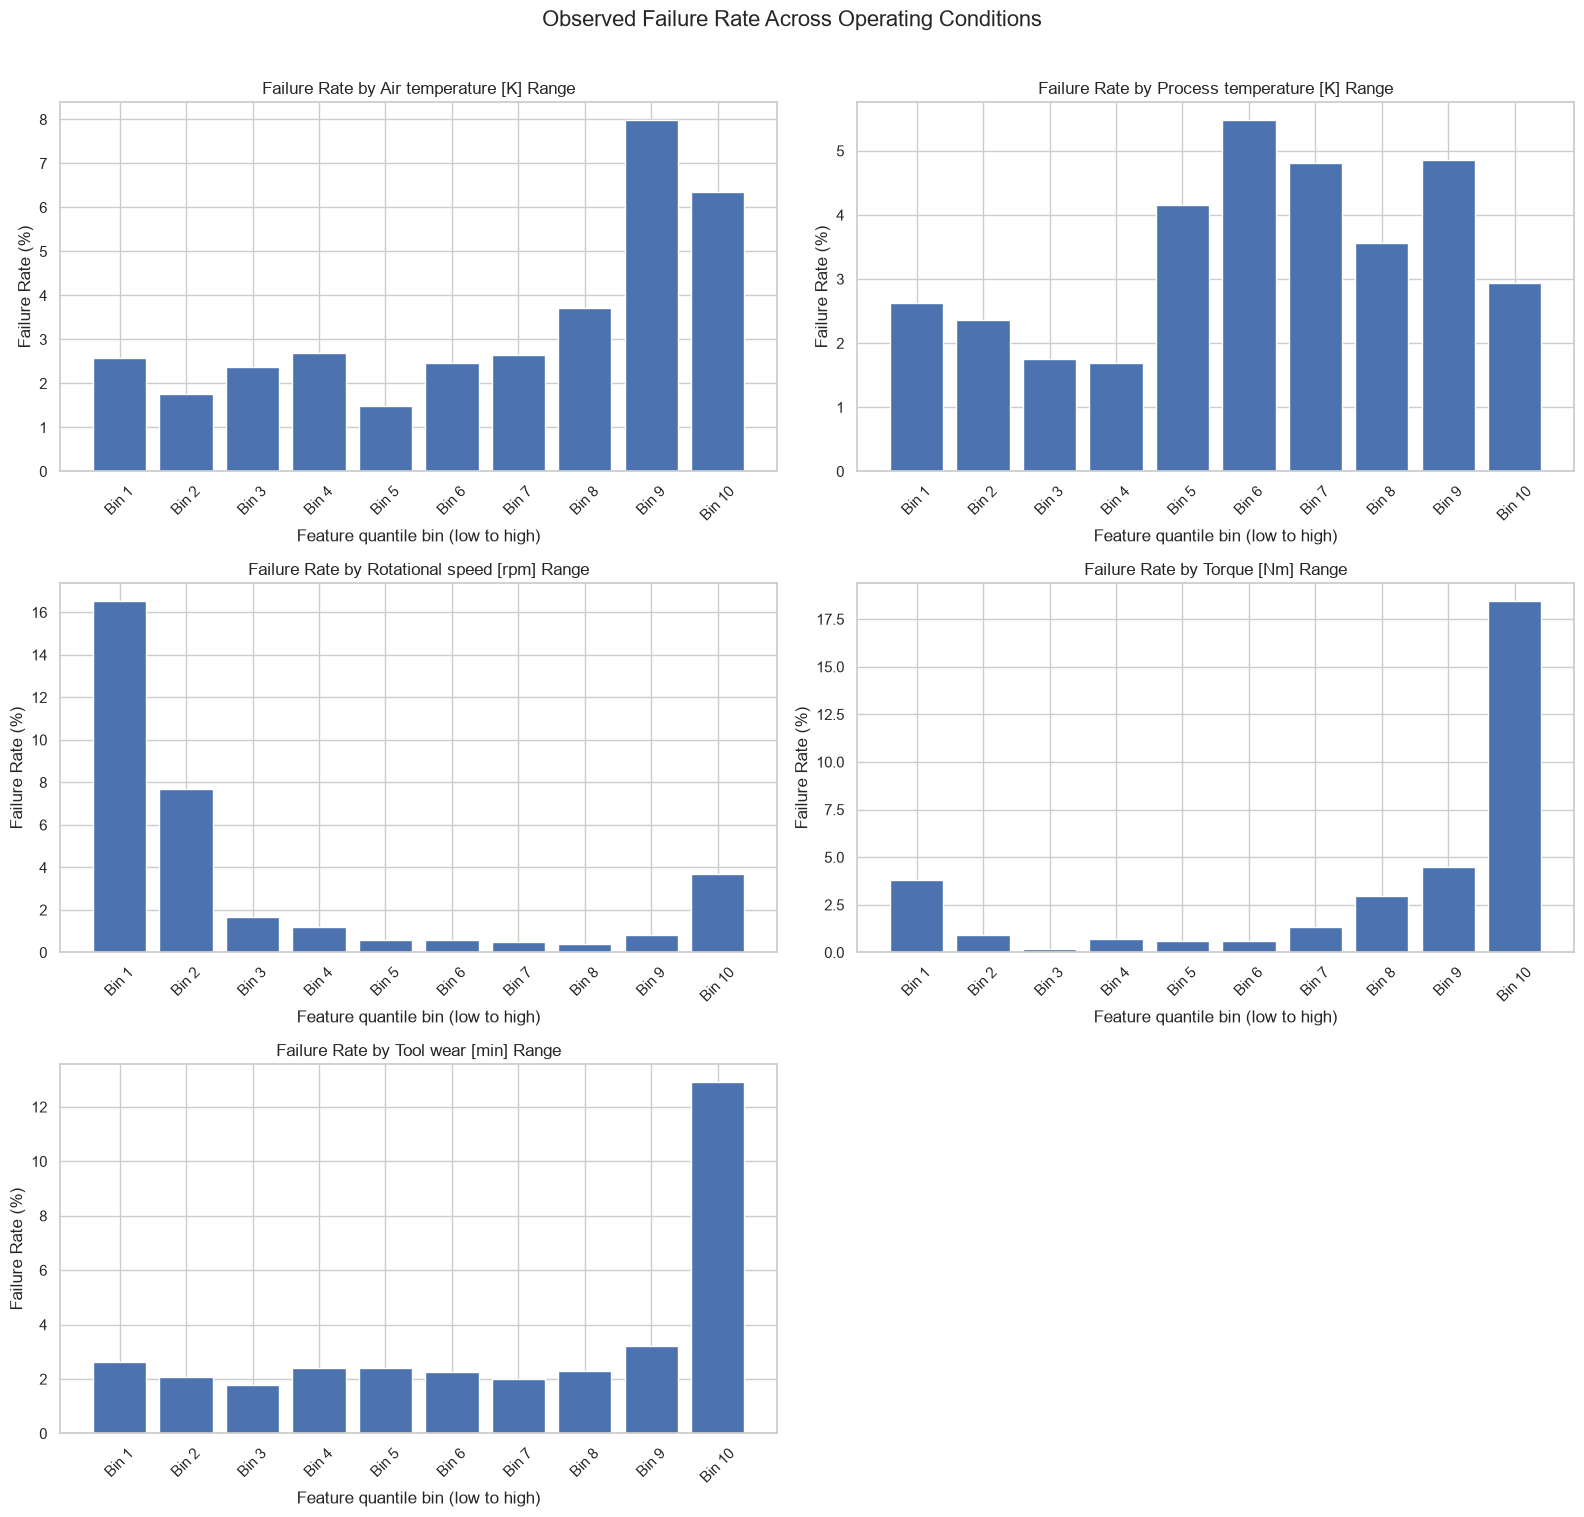

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\failure_rate_by_feature_bins.png


In [31]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for i, feature in enumerate(NUMERICAL_FEATURES):
    grouped = failure_rate_by_bins[feature]

    x_labels = [
        f"Bin {j + 1}"
        for j in range(len(grouped))
    ]

    axes[i].bar(
        x_labels,
        grouped["failure_rate_pct"],
    )

    axes[i].set_title(f"Failure Rate by {feature} Range")
    axes[i].set_xlabel("Feature quantile bin (low to high)")
    axes[i].set_ylabel("Failure Rate (%)")
    axes[i].tick_params(axis="x", rotation=45)

fig.delaxes(axes[-1])

fig.suptitle(
    "Observed Failure Rate Across Operating Conditions",
    fontsize=16,
    y=1.01,
)

plt.tight_layout()

plot_path = PLOTS_DIR / "failure_rate_by_feature_bins.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [32]:
CORRELATION_COLUMNS = NUMERICAL_FEATURES + [TARGET_COLUMN]

correlation_df = df[CORRELATION_COLUMNS].copy()

print("Columns included in correlation analysis:")
display(correlation_df.head())

print(f"Shape: {correlation_df.shape}")

Columns included in correlation analysis:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,298.100,308.600,1551,42.800,0,0
1,298.200,308.700,1408,46.300,3,0
2,298.100,308.500,1498,49.400,5,0
3,298.200,308.600,1433,39.500,7,0
4,298.200,308.700,1408,40.000,9,0


Shape: (10000, 6)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000,0.876,0.023,-0.014,0.014,0.083
Process temperature [K],0.876,1.000,0.019,-0.014,0.013,0.036
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000,-0.044
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003,0.191
Tool wear [min],0.014,0.013,0.000,-0.003,1.000,0.105
Machine failure,0.083,0.036,-0.044,0.191,0.105,1.000


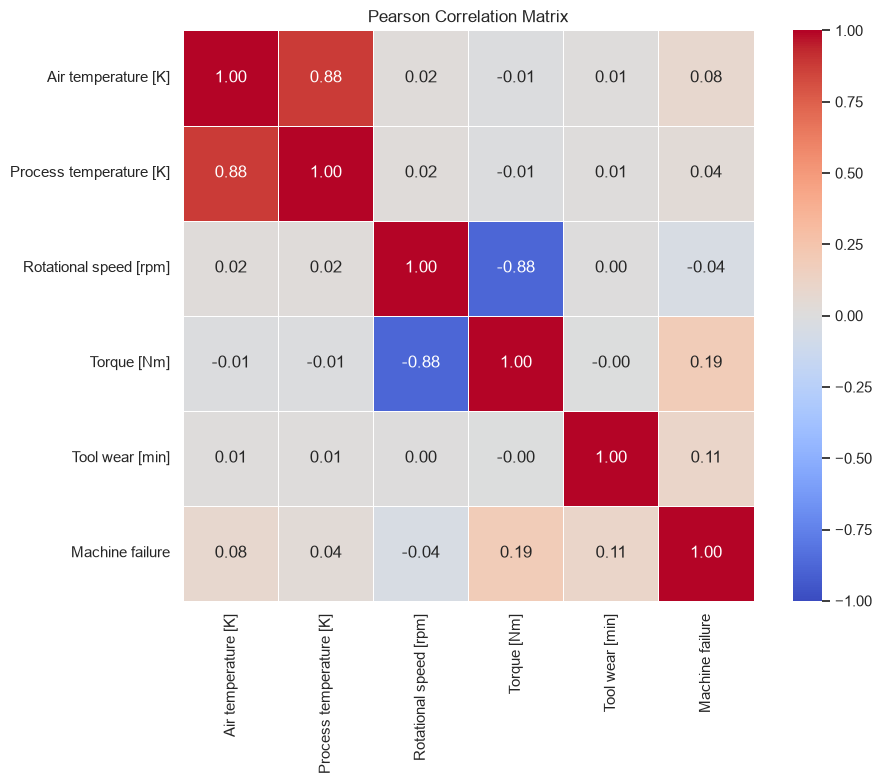

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\pearson_correlation_matrix.png


In [33]:
pearson_corr = correlation_df.corr(method="pearson")

display(pearson_corr.round(3))

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title("Pearson Correlation Matrix")

plt.tight_layout()

plot_path = PLOTS_DIR / "pearson_correlation_matrix.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000,0.864,0.014,-0.012,0.013,0.083
Process temperature [K],0.864,1.000,0.017,-0.014,0.014,0.040
Rotational speed [rpm],0.014,0.017,1.000,-0.916,0.003,-0.167
Torque [Nm],-0.012,-0.014,-0.916,1.000,-0.004,0.169
Tool wear [min],0.013,0.014,0.003,-0.004,1.000,0.102
Machine failure,0.083,0.040,-0.167,0.169,0.102,1.000


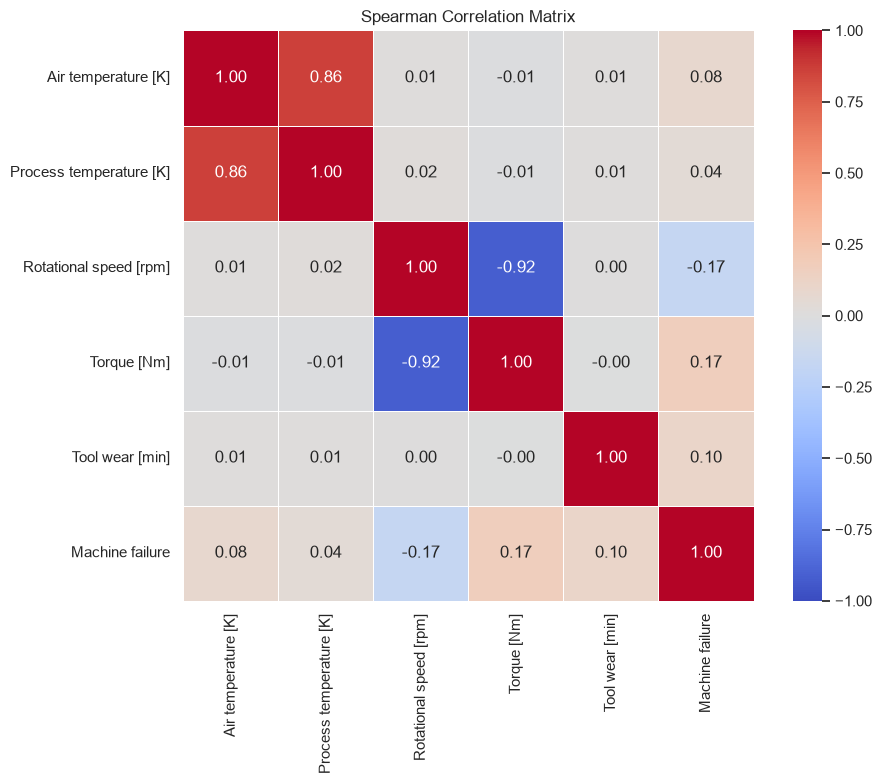

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\spearman_correlation_matrix.png


In [34]:
spearman_corr = correlation_df.corr(method="spearman")

display(spearman_corr.round(3))

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title("Spearman Correlation Matrix")

plt.tight_layout()

plot_path = PLOTS_DIR / "spearman_correlation_matrix.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [35]:
FEATURE_CORRELATION_THRESHOLD = 0.80

feature_corr = df[NUMERICAL_FEATURES].corr(method="pearson")

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_correlation_pairs = []

for column in upper_triangle.columns:
    for row in upper_triangle.index:
        value = upper_triangle.loc[row, column]

        if pd.notna(value) and abs(value) >= FEATURE_CORRELATION_THRESHOLD:
            high_correlation_pairs.append({
                "feature_1": row,
                "feature_2": column,
                "pearson_correlation": value,
                "absolute_correlation": abs(value),
            })

high_corr_df = pd.DataFrame(
    high_correlation_pairs,
    columns=[
        "feature_1",
        "feature_2",
        "pearson_correlation",
        "absolute_correlation",
    ],
)

if high_corr_df.empty:
    print(
        "No numerical feature pairs met the absolute Pearson "
        f"correlation threshold of {FEATURE_CORRELATION_THRESHOLD:.2f}."
    )
else:
    display(high_corr_df.sort_values(
        "absolute_correlation",
        ascending=False,
    ))

high_corr_path = REPORTS_DIR / "high_correlation_pairs.csv"
high_corr_df.to_csv(high_corr_path, index=False)

print(f"Correlation-pair report saved to: {high_corr_path}")


,feature_1,feature_2,pearson_correlation,absolute_correlation
0,Air temperature [K],Process temperature [K],0.876,0.876
1,Rotational speed [rpm],Torque [Nm],-0.875,0.875


Correlation-pair report saved to: d:\robotic-predictive-maintenance\artifacts\reports\high_correlation_pairs.csv


,temperature_difference
count,10000.000
mean,10.001
std,1.001
min,7.600
25%,9.300
50%,9.800
75%,11.000
max,12.100


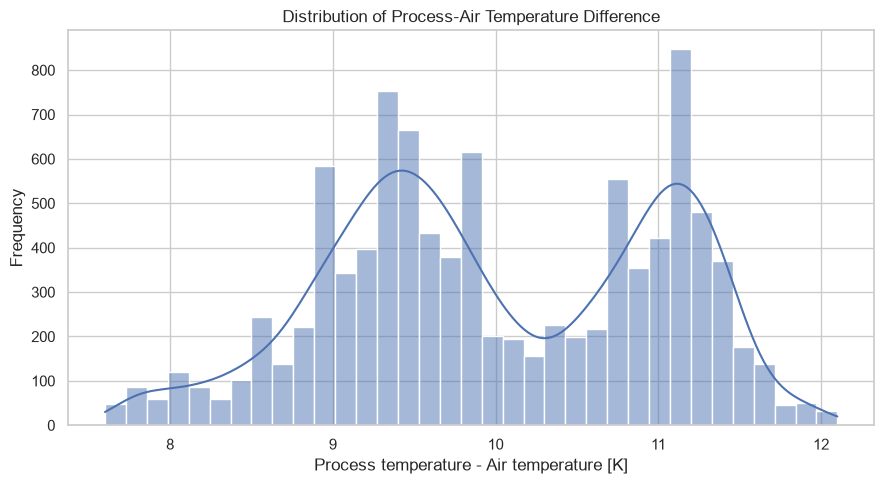

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\temperature_difference_distribution.png


In [36]:
df_eda = df.copy()

df_eda["Temperature difference [K]"] = (
    df_eda["Process temperature [K]"]
    - df_eda["Air temperature [K]"]
)

display(
    df_eda["Temperature difference [K]"]
    .describe()
    .to_frame("temperature_difference")
    .round(3)
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=df_eda,
    x="Temperature difference [K]",
    bins=35,
    kde=True,
    ax=ax,
)

ax.set_title("Distribution of Process-Air Temperature Difference")
ax.set_xlabel("Process temperature - Air temperature [K]")
ax.set_ylabel("Frequency")

plt.tight_layout()

plot_path = PLOTS_DIR / "temperature_difference_distribution.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [37]:
failure_mode_summary = pd.DataFrame({
    "failure_count": df[FAILURE_MODE_COLUMNS].sum(),
    "failure_rate_pct": df[FAILURE_MODE_COLUMNS].mean() * 100,
})

failure_mode_summary.index.name = "Failure Mode"

display(
    failure_mode_summary.sort_values(
        "failure_count",
        ascending=False,
    ).round(3)
)

failure_mode_path = REPORTS_DIR / "failure_mode_summary.csv"
failure_mode_summary.to_csv(failure_mode_path)

print(f"Summary saved to: {failure_mode_path}")


,failure_count,failure_rate_pct
Failure Mode,,
HDF,115,1.150
OSF,98,0.980
PWF,95,0.950
TWF,46,0.460
RNF,19,0.190


Summary saved to: d:\robotic-predictive-maintenance\artifacts\reports\failure_mode_summary.csv


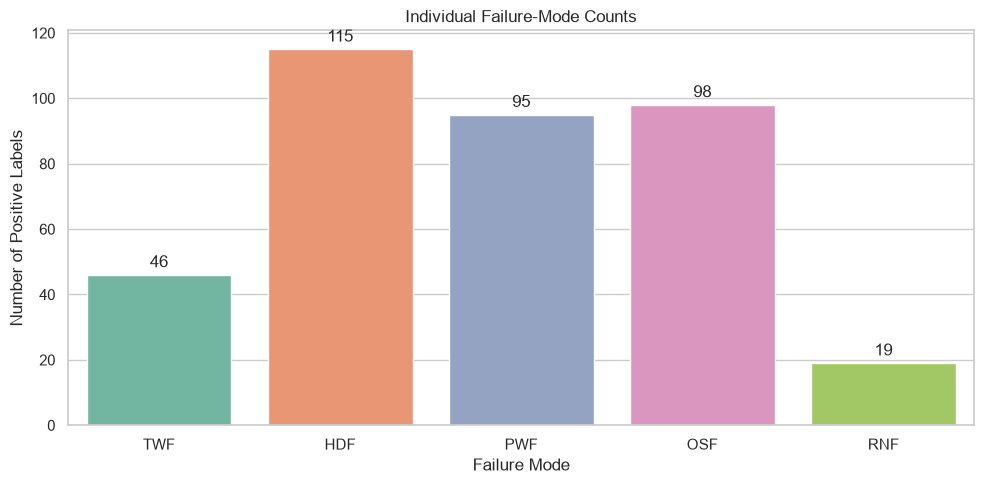

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\failure_mode_counts.png


In [38]:
plot_data = failure_mode_summary.reset_index()

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot_data,
    x="Failure Mode",
    y="failure_count",
    hue="Failure Mode",
    order=FAILURE_MODE_COLUMNS,
    palette="Set2",
    legend=False,
    ax=ax,
)

ax.set_title("Individual Failure-Mode Counts")
ax.set_xlabel("Failure Mode")
ax.set_ylabel("Number of Positive Labels")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()

plot_path = PLOTS_DIR / "failure_mode_counts.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [40]:
failure_mode_flags = df[FAILURE_MODE_COLUMNS].eq(1)

failure_mode_flags["number_of_failure_modes"] = (
    failure_mode_flags[FAILURE_MODE_COLUMNS]
    .sum(axis=1)
)

overlap_counts = (
    failure_mode_flags["number_of_failure_modes"]
    .value_counts()
    .sort_index()
)

overlap_summary = pd.DataFrame({
    "observations": overlap_counts,
    "percentage": overlap_counts / len(df) * 100,
})

overlap_summary.index.name = "Number of Positive Failure Modes"

In [41]:
pearson_path = REPORTS_DIR / "pearson_correlation.csv"
spearman_path = REPORTS_DIR / "spearman_correlation.csv"

pearson_corr.to_csv(pearson_path)
spearman_corr.to_csv(spearman_path)

print(f"Pearson matrix saved: {pearson_path}")
print(f"Spearman matrix saved: {spearman_path}")
print("Correlation outputs saved successfully.")


Pearson matrix saved: d:\robotic-predictive-maintenance\artifacts\reports\pearson_correlation.csv
Spearman matrix saved: d:\robotic-predictive-maintenance\artifacts\reports\spearman_correlation.csv
Correlation outputs saved successfully.


In [42]:
type_feature_summary = (
    df.groupby("Type", observed=True)[NUMERICAL_FEATURES]
    .agg(["mean", "median", "std"])
)

display(type_feature_summary.round(3))

Air temperature [K]               Process temperature [K]                \
                    mean  median   std                    mean  median   std   
Type                                                                           
H                299.867 299.800 2.022                 309.926 309.900 1.489   
L                300.016 300.100 1.987                 310.012 310.100 1.475   
M                300.029 300.100 2.017                 310.019 310.000 1.498   

     Rotational speed [rpm]                  Torque [Nm]                \
                       mean   median     std        mean median    std   
Type                                                                     
H                  1538.148 1500.000 173.133      39.838 40.300  9.642   
L                  1539.469 1504.000 180.429      39.997 40.000 10.012   
M                  1537.599 1503.000 179.060      40.017 40.200  9.992   

     Tool wear [min]                 
                mean  median    std  
Type                                 
H            107.420 107.000 63.080  
L            108.379 109.000 64.058  
M            107.272 106.000 63.045

,TWF,HDF,PWF,OSF,RNF
TWF,46.000,0.000,1.000,3.000,1.000
HDF,0.000,115.000,3.000,6.000,0.000
PWF,1.000,3.000,95.000,12.000,0.000
OSF,3.000,6.000,12.000,98.000,0.000
RNF,1.000,0.000,0.000,0.000,19.000


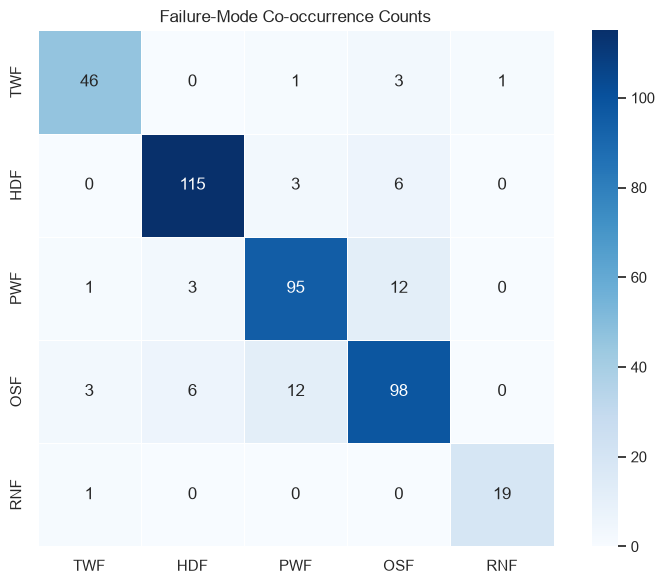

Plot saved to: d:\robotic-predictive-maintenance\artifacts\plots\failure_mode_overlap.png


In [43]:
mode_overlap = pd.DataFrame(
    index=FAILURE_MODE_COLUMNS,
    columns=FAILURE_MODE_COLUMNS,
    dtype=int,
)

for mode_a in FAILURE_MODE_COLUMNS:
    for mode_b in FAILURE_MODE_COLUMNS:
        mode_overlap.loc[mode_a, mode_b] = int(
            ((df[mode_a] == 1) & (df[mode_b] == 1)).sum()
        )

display(mode_overlap)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    mode_overlap,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title("Failure-Mode Co-occurrence Counts")

plt.tight_layout()

plot_path = PLOTS_DIR / "failure_mode_overlap.png"
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Plot saved to: {plot_path}")


In [44]:
eda_quality_summary = {
    "dataset_rows": len(df),
    "dataset_columns": len(df.columns),
    "missing_values": int(df.isnull().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_udi": int(df["UDI"].duplicated().sum()),
    "machine_failures": int(df[TARGET_COLUMN].sum()),
    "machine_failure_rate_pct": float(df[TARGET_COLUMN].mean() * 100),
    "label_disagreements": int(df_eda_check["label_mismatch"].sum()),
}

quality_report_path = REPORTS_DIR / "eda_quality_summary.csv"

pd.Series(eda_quality_summary, name="value").to_csv(
    quality_report_path,
    header=True,
)

display(pd.Series(eda_quality_summary, name="value").to_frame())

print(f"Quality summary saved to: {quality_report_path}")


,value
dataset_rows,10000.000
dataset_columns,14.000
missing_values,0.000
duplicate_rows,0.000
duplicate_udi,0.000
machine_failures,339.000
machine_failure_rate_pct,3.390
label_disagreements,27.000


Quality summary saved to: d:\robotic-predictive-maintenance\artifacts\reports\eda_quality_summary.csv
